# Week1 - Weekly Assessment

## Task 1 - Python Core,OOP and Errors

In [34]:
import csv

# Read employee data
with open("../data/employees.csv", "r") as file:
    employees = list(csv.DictReader(file))


# 1. Function with *args and **kwargs
def bonus(salary, rate=0.1, *extras, **options):
    result = salary * rate + sum(extras)

    if "cap" in options:
        result = min(result, options["cap"])

    return result


print("Bonus:", bonus(50000, 0.1, 500, 1000, cap=6000))


# 2. Custom exception
class InvalidSalaryError(Exception):
    pass


# 3. Employee class
class Employee:

    def __init__(self, name, salary):
        if salary < 0:
            raise InvalidSalaryError(
                f"Invalid salary: {salary}"
            )

        self.name = name
        self.salary = salary

    def annual_salary(self):
        return self.salary * 12

    def get_details(self):
        return f"{self.name} - {self.salary}"


# 4. Manager inheritance
class Manager(Employee):

    def __init__(self, name, salary, team_size):
        super().__init__(name, salary)
        self.team_size = team_size

    def get_details(self):
        return (
            f"{self.name} - {self.salary} "
            f"- Team size: {self.team_size}"
        )


# Test Employee and Manager
emp = Employee("Arun", 30000)
print(emp.get_details())
print("Annual salary:", emp.annual_salary())

manager = Manager("Priya", 60000, 5)
print(manager.get_details())


# 5. Handle invalid salary
try:
    emp = Employee("Test", -500)

except InvalidSalaryError as e:
    print("Error:", e)

finally:
    print("Transaction finished")


# 6. List comprehension: salary above 50000
above_50000 = [
    emp["name"]
    for emp in employees
    if int(emp["salary"]) > 50000
]

print("Above 50000:", above_50000)


# 7. Map and lambda: 10% salary increase
raised_salaries = list(
    map(
        lambda emp: int(emp["salary"]) * 1.10,
        employees
    )
)

print("10% Raised Salaries:", raised_salaries)


# 8. Filter Chennai employees
chennai_employees = list(
    filter(
        lambda emp: emp["city"] == "Chennai",
        employees
    )
)

print(
    "Chennai:",
    [emp["name"] for emp in chennai_employees]
)


# 9. Continue and break
salaries = [
    int(emp["salary"]) for emp in employees
]

for salary in salaries:

    if salary == 0:
        continue

    if salary > 85000:
        break

    print("Salary:", salary)

Bonus: 6000
Arun - 30000
Annual salary: 360000
Priya - 60000 - Team size: 5
Error: Invalid salary: -500
Transaction finished
Above 50000: ['Rahul', 'Divya', 'Karthik', 'Meena', 'Suresh']
10% Raised Salaries: [33000.0, 49500.00000000001, 66000.0, 82500.0, 99000.00000000001, 57200.00000000001, 74800.0, 52800.00000000001]
Chennai: ['Arun', 'Priya', 'Divya', 'Suresh']
Salary: 30000
Salary: 45000
Salary: 60000
Salary: 75000


# Task 2 - Files,APIs and Environment

In [35]:

import csv
import json

# Read employees.csv
with open("../data/employees.csv", "r") as file:
    employees = list(csv.DictReader(file))

print("Rows read:", len(employees))


# Create employees.json
with open("../data/employees.json", "w") as file:
    json.dump(employees, file, indent=4)


# Find employees earning above 50000
high_earners = [
    emp for emp in employees
    if int(emp["salary"]) > 50000
]


# Create high_earners.csv
with open(
    "../data/high_earners.csv",
    "w",
    newline=""
) as file:

    writer = csv.DictWriter(
        file,
        fieldnames=employees[0].keys()
    )

    writer.writeheader()
    writer.writerows(high_earners)


print("High earners:", len(high_earners))
print("Files created successfully!")


Rows read: 8
High earners: 5
Files created successfully!


In [36]:

import os
import json
import requests
from dotenv import load_dotenv

# Load environment variables
load_dotenv("../.env")

API_KEY = os.getenv("API_KEY")

print("API key loaded:", API_KEY is not None)


# GET request
url = "https://jsonplaceholder.typicode.com/users"

try:
    response = requests.get(url, timeout=5)
    response.raise_for_status()

    users = response.json()

    # Print first 3 users
    for user in users[:3]:
        print(
            user.get("id"),
            "-",
            user.get("name"),
            "-",
            user.get("email")
        )

    # Extract nested JSON using get()
    selected_users = []

    for user in users[:3]:
        selected_users.append({
            "id": user.get("id"),
            "name": user.get("name"),
            "email": user.get("email"),
            "city": user.get("address", {}).get("city")
        })

    # Save users.json
    with open("../data/users.json", "w") as file:
        json.dump(selected_users, file, indent=4)

    print("users.json created successfully")

except requests.exceptions.Timeout:
    print("Request timed out")

except requests.exceptions.ConnectionError:
    print("Connection error")

except requests.exceptions.HTTPError as e:
    print("HTTP Error:", e)


# Test 404 error
try:
    response = requests.get(
        "https://jsonplaceholder.typicode.com/users/9999",
        timeout=5
    )

    if response.status_code == 404:
        print("/users/9999 -> 404 Not found")
    else:
        response.raise_for_status()

except requests.exceptions.Timeout:
    print("Request timed out")

except requests.exceptions.ConnectionError:
    print("Connection error")

except requests.exceptions.HTTPError as e:
    print("HTTP Error:", e)


API key loaded: True
1 - Leanne Graham - Sincere@april.biz
2 - Ervin Howell - Shanna@melissa.tv
3 - Clementine Bauch - Nathan@yesenia.net
users.json created successfully
/users/9999 -> 404 Not found


## Task 3 - NumPy, Pandas and Matplotlib

### NumPy Array Operations

In [37]:

import numpy as np

# Create marks array (4 students x 3 subjects)
marks = np.array([
    [80, 75, 90],
    [70, 85, 80],
    [90, 95, 85],
    [60, 70, 75]
])

# Print array shape
print("Shape:", marks.shape)

# Student averages (axis=1)
student_avg = np.mean(marks, axis=1)
print("Student averages:", student_avg)

# Subject averages (axis=0)
subject_avg = np.mean(marks, axis=0)
print("Subject averages:", subject_avg)

# Add 5 grace marks using broadcasting
grace_marks = marks + 5
print("Grace marks:\n", grace_marks)

# Calculate weighted scores using np.dot
weights = np.array([0.3, 0.3, 0.4])

weighted_scores = np.dot(grace_marks, weights)

print("Weighted scores:", weighted_scores)


Shape: (4, 3)
Student averages: [81.66666667 78.33333333 90.         68.33333333]
Subject averages: [75.   81.25 82.5 ]
Grace marks:
 [[ 85  80  95]
 [ 75  90  85]
 [ 95 100  90]
 [ 65  75  80]]
Weighted scores: [87.5 83.5 94.5 74. ]


### Pandas Data Analysis

In [38]:

import pandas as pd

# Load employee CSV
df = pd.read_csv("../data/employees.csv")

# Display first five records
print("Employee Data:")
print(df.head())

# Display DataFrame information
print("\nDataFrame Information:")
df.info()

# Statistical description
print("\nStatistical Description:")
print(df.describe())

# Using loc
print("\nUsing loc:")
print(df.loc[0:2, ["name", "salary"]])

# Using iloc
print("\nUsing iloc:")
print(df.iloc[0:3, 0:3])

# Filtering employees with salary above 50000
print("\nEmployees earning above 50000:")
print(df[df["salary"] > 50000])


Employee Data:
   id     name department  salary       city
0   1     Arun      Sales   30000    Chennai
1   2    Priya         HR   45000    Chennai
2   3    Rahul         IT   60000  Bangalore
3   4    Divya         IT   75000    Chennai
4   5  Karthik    Finance   90000     Mumbai

DataFrame Information:
<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   id          8 non-null      int64
 1   name        8 non-null      str  
 2   department  8 non-null      str  
 3   salary      8 non-null      int64
 4   city        8 non-null      str  
dtypes: int64(2), str(3)
memory usage: 452.0 bytes

Statistical Description:
            id        salary
count  8.00000      8.000000
mean   4.50000  58500.000000
std    2.44949  18913.336187
min    1.00000  30000.000000
25%    2.75000  47250.000000
50%    4.50000  56000.000000
75%    6.25000  69750.000000
max    8.00000  9000

### Data Cleaning - Missing Values and Duplicates

In [39]:

# Create a working copy of employee data
clean_df = df.copy()

# Add two missing salary values
clean_df.loc[0, "salary"] = np.nan
clean_df.loc[1, "salary"] = np.nan

# Add one duplicate row
clean_df = pd.concat(
    [clean_df, clean_df.iloc[[2]]],
    ignore_index=True
)

print("Before cleaning:")
print(clean_df)

# Remove duplicate rows
clean_df = clean_df.drop_duplicates()

# Calculate median salary
median_salary = clean_df["salary"].median()

# Fill missing salaries using median
clean_df["salary"] = clean_df["salary"].fillna(
    median_salary
)

# Correct data types
clean_df["id"] = clean_df["id"].astype(int)
clean_df["salary"] = clean_df["salary"].astype(int)

print("\nAfter cleaning:")
print(clean_df)

# Check missing values
print("\nMissing values:")
print(clean_df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", clean_df.duplicated().sum())


Before cleaning:
   id     name department   salary       city
0   1     Arun      Sales      NaN    Chennai
1   2    Priya         HR      NaN    Chennai
2   3    Rahul         IT  60000.0  Bangalore
3   4    Divya         IT  75000.0    Chennai
4   5  Karthik    Finance  90000.0     Mumbai
5   6    Meena      Sales  52000.0  Bangalore
6   7   Suresh         IT  68000.0    Chennai
7   8   Anitha         HR  48000.0     Mumbai
8   3    Rahul         IT  60000.0  Bangalore

After cleaning:
   id     name department  salary       city
0   1     Arun      Sales   64000    Chennai
1   2    Priya         HR   64000    Chennai
2   3    Rahul         IT   60000  Bangalore
3   4    Divya         IT   75000    Chennai
4   5  Karthik    Finance   90000     Mumbai
5   6    Meena      Sales   52000  Bangalore
6   7   Suresh         IT   68000    Chennai
7   8   Anitha         HR   48000     Mumbai

Missing values:
id            0
name          0
department    0
salary        0
city          0
dtyp

### Department Grouping and Aggregation

In [40]:

# Group employees by department
department_summary = clean_df.groupby(
    "department"
).agg(
    headcount=("name", "count"),
    average_salary=("salary", "mean"),
    maximum_salary=("salary", "max")
)

# Display department summary
print("Department Summary:")
print(department_summary)

# Display headcount separately
print("\nDepartment Headcount:")
print(department_summary["headcount"])


Department Summary:
            headcount  average_salary  maximum_salary
department                                           
Finance             1    90000.000000           90000
HR                  2    56000.000000           64000
IT                  3    67666.666667           75000
Sales               2    58000.000000           64000

Department Headcount:
department
Finance    1
HR         2
IT         3
Sales      2
Name: headcount, dtype: int64


### Department Merging - Inner, Left and Outer Joins

In [41]:

# Load departments.csv
departments = pd.read_csv("../data/departments.csv")

# 1. INNER JOIN
inner_result = pd.merge(
    clean_df,
    departments,
    on="department",
    how="inner"
)

print("INNER JOIN:")
print(inner_result)


# 2. LEFT JOIN
left_result = pd.merge(
    clean_df,
    departments,
    on="department",
    how="left"
)

print("\nLEFT JOIN:")
print(left_result)


# 3. OUTER JOIN
outer_result = pd.merge(
    clean_df,
    departments,
    on="department",
    how="outer"
)

print("\nOUTER JOIN:")
print(outer_result)


# Find department without employees
departments_without_employees = outer_result[
    outer_result["name"].isna()
]["department"].unique()

print(
    "\nDepartment without employees:",
    departments_without_employees
)


INNER JOIN:
   id     name department  salary       city       head  budget
0   1     Arun      Sales   64000    Chennai  Manager A  500000
1   2    Priya         HR   64000    Chennai  Manager B  300000
2   3    Rahul         IT   60000  Bangalore  Manager C  800000
3   4    Divya         IT   75000    Chennai  Manager C  800000
4   5  Karthik    Finance   90000     Mumbai  Manager D  400000
5   6    Meena      Sales   52000  Bangalore  Manager A  500000
6   7   Suresh         IT   68000    Chennai  Manager C  800000
7   8   Anitha         HR   48000     Mumbai  Manager B  300000

LEFT JOIN:
   id     name department  salary       city       head  budget
0   1     Arun      Sales   64000    Chennai  Manager A  500000
1   2    Priya         HR   64000    Chennai  Manager B  300000
2   3    Rahul         IT   60000  Bangalore  Manager C  800000
3   4    Divya         IT   75000    Chennai  Manager C  800000
4   5  Karthik    Finance   90000     Mumbai  Manager D  400000
5   6    Meena  

### Data Visualization - Four Charts

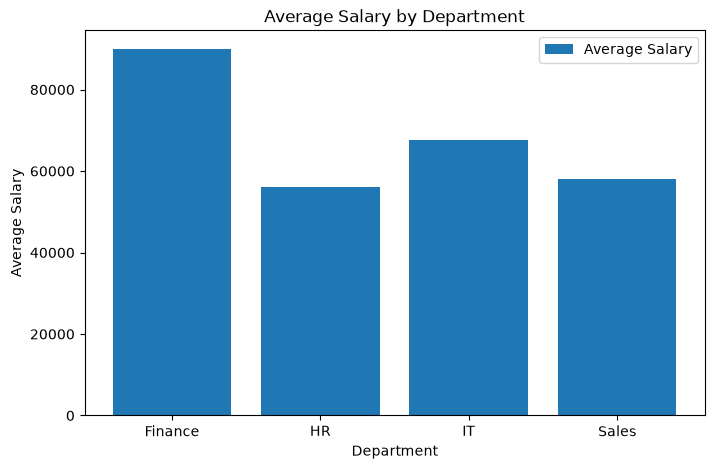

Insight: IT has the highest average salary.


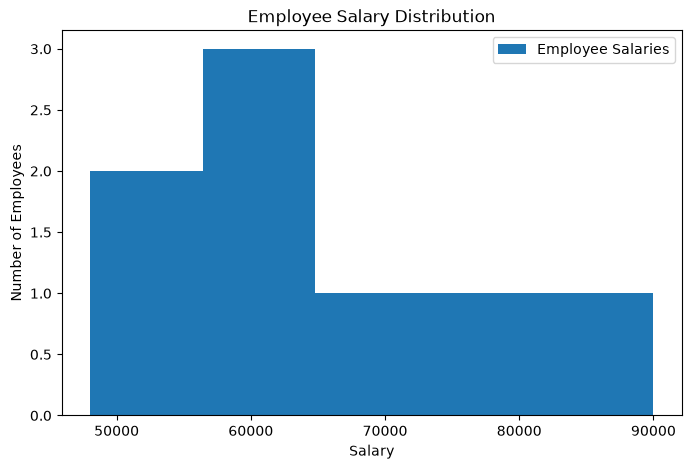

Insight: The histogram shows the distribution of employee salaries.


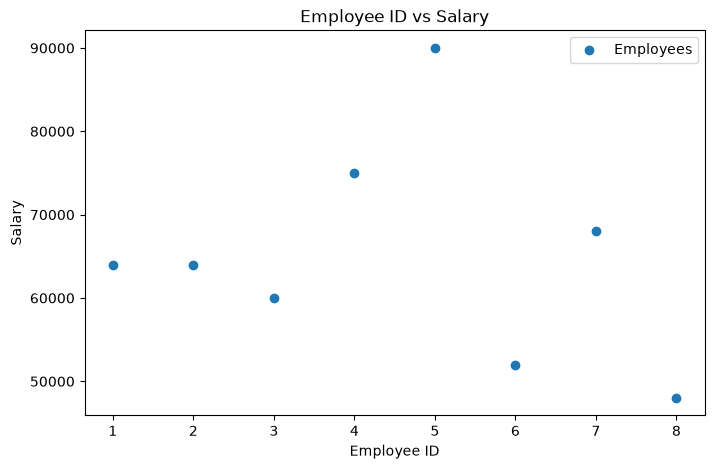

Insight: The scatter chart compares employee IDs with salaries.


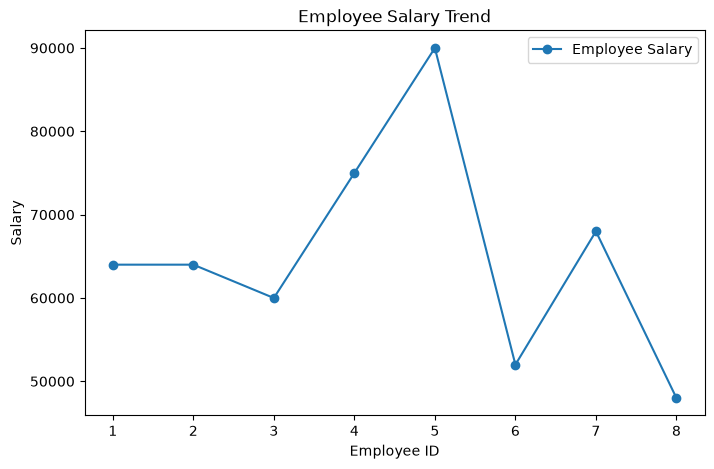

Insight: The line chart displays salary changes across employee IDs.


In [42]:

import matplotlib.pyplot as plt

# 1. BAR CHART - Average salary by department
department_salary = clean_df.groupby(
    "department"
)["salary"].mean()

plt.figure(figsize=(8, 5))

plt.bar(
    department_salary.index,
    department_salary.values,
    label="Average Salary"
)

plt.title("Average Salary by Department")
plt.xlabel("Department")
plt.ylabel("Average Salary")
plt.legend()

plt.savefig("../reports/bar_chart.png")
plt.show()

print("Insight: IT has the highest average salary.")


# 2. HISTOGRAM - Salary distribution
plt.figure(figsize=(8, 5))

plt.hist(
    clean_df["salary"],
    bins=5,
    label="Employee Salaries"
)

plt.title("Employee Salary Distribution")
plt.xlabel("Salary")
plt.ylabel("Number of Employees")
plt.legend()

plt.savefig("../reports/histogram.png")
plt.show()

print("Insight: The histogram shows the distribution of employee salaries.")


# 3. SCATTER CHART - Employee ID vs Salary
plt.figure(figsize=(8, 5))

plt.scatter(
    clean_df["id"],
    clean_df["salary"],
    label="Employees"
)

plt.title("Employee ID vs Salary")
plt.xlabel("Employee ID")
plt.ylabel("Salary")
plt.legend()

plt.savefig("../reports/scatter_chart.png")
plt.show()

print("Insight: The scatter chart compares employee IDs with salaries.")


# 4. LINE CHART - Employee salary trend
plt.figure(figsize=(8, 5))

plt.plot(
    clean_df["id"],
    clean_df["salary"],
    marker="o",
    label="Employee Salary"
)

plt.title("Employee Salary Trend")
plt.xlabel("Employee ID")
plt.ylabel("Salary")
plt.legend()

plt.savefig("../reports/line_chart.png")
plt.show()

print("Insight: The line chart displays salary changes across employee IDs.")


## Task 4 - Git, Terminal and Notebook

### Git Operations

### Terminal Commands

### Performance Testing

### Final Results

In [43]:
# Performance testing using timeit

numbers = list(range(1000))

%timeit sum(numbers)

6.52 μs ± 44.5 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)
